# Exercício: Random Forest e AdaBoost

Use `load_breast_cancer()` do scikit-learn. Neste conjunto, `0 = maligno` e `1 = benigno`. Adote `random_state=42`. Entregue o notebook com código executado e respostas fundamentadas nos resultados. Trata-se de dados didáticos; a comparação não constitui validação clínica.

## Questão 1 — Conheça e prepare os dados
- Carregue o conjunto em um `DataFrame` com os 30 atributos e a variável alvo. Informe dimensões, tipos, valores ausentes, linhas duplicadas e quantidade por classe.
-  Descreva o tratamento necessário (ou explique por que nenhum é necessário). Separe treino (60%), validação (20%) e teste (20%) de modo estratificado; mantenha o teste reservado para a questão 5. Por que preservar a proporção das classes?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.base import clone
from sklearn.model_selection import (train_test_split, RandomizedSearchCV,
                                     StratifiedKFold, cross_val_score)
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, make_scorer)
from scipy.stats import randint, uniform

RANDOM_STATE = 42
N_JOBS = 8

dados = load_breast_cancer(as_frame=True)
df = dados.frame.copy()  # 30 atributos + coluna 'target'
print("Dimensões:", df.shape)
df.head()

Dimensões: (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [2]:
print("Tipos de dados:")
print(df.dtypes.value_counts(), "\n")
print("Valores ausentes (total):", df.isna().sum().sum())
print("Linhas duplicadas:", df.duplicated().sum(), "\n")
contagem = df["target"].value_counts().sort_index()
print(pd.DataFrame({"classe": ["maligno", "benigno"], "quantidade": contagem.values,
                    "proporção": (contagem / len(df)).round(3).values}, index=contagem.index))

Tipos de dados:
float64    30
int64       1
Name: count, dtype: int64 

Valores ausentes (total): 0
Linhas duplicadas: 0 

         classe  quantidade  proporção
target                                
0       maligno         212      0.373
1       benigno         357      0.627


In [3]:
df.describe().T[["mean", "std", "min", "max"]].head(10)

,mean,std,min,max
mean radius,14.127292,3.524049,6.98100,28.11000
mean texture,19.289649,4.301036,9.71000,39.28000
mean perimeter,91.969033,24.298981,43.79000,188.50000
mean area,654.889104,351.914129,143.50000,2501.00000
mean smoothness,0.096360,0.014064,0.05263,0.16340
mean compactness,0.104341,0.052813,0.01938,0.34540
mean concavity,0.088799,0.079720,0.00000,0.42680
mean concave points,0.048919,0.038803,0.00000,0.20120
mean symmetry,0.181162,0.027414,0.10600,0.30400
mean fractal dimension,0.062798,0.007060,0.04996,0.09744


In [4]:
X = df.drop(columns="target")
y = df["target"]

# 60% treino, 20% validação, 20% teste — todos estratificados
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=RANDOM_STATE)  # 0.25 * 0.8 = 0.2

resumo = pd.DataFrame({
    "amostras": [len(y_train), len(y_val), len(y_test)],
    "malignos (0)": [(y_train == 0).sum(), (y_val == 0).sum(), (y_test == 0).sum()],
    "benignos (1)": [(y_train == 1).sum(), (y_val == 1).sum(), (y_test == 1).sum()],
    "% maligno": [round((s == 0).mean() * 100, 1) for s in (y_train, y_val, y_test)],
}, index=["treino", "validação", "teste"])
resumo

,amostras,malignos (0),benignos (1),% maligno
treino,341,127,214,37.2
validação,114,43,71,37.7
teste,114,42,72,36.8


### Resposta — Questão 1

**Caracterização dos dados**
- **Dimensões:** 569 linhas × 31 colunas (30 atributos + `target`).
- **Tipos:** os 30 atributos são `float64` (medidas contínuas dos núcleos celulares); `target` é `int64` (0/1).
- **Valores ausentes:** 0. **Linhas duplicadas:** 0.
- **Classes:** 212 malignos (37,3%) e 357 benignos (62,7%). Há um desbalanceamento moderado (~1 : 1,7).

**Tratamento necessário:** nenhum tratamento de limpeza é necessário. Não há ausentes nem duplicatas, e todos os atributos já são numéricos, então não há codificação de categorias. As escalas são bem diferentes (por exemplo, `mean area` vai até 2501 e `mean smoothness` fica perto de 0,1), mas Random Forest e AdaBoost usam árvores de decisão. Árvores dividem cada atributo por limiares e não são afetadas por transformações monotônicas de escala, então normalizar ou padronizar não muda o resultado. O desbalanceamento é tratado com a divisão estratificada e com métricas focadas na classe maligna (precision, recall e F1 com `pos_label=0`), em vez de só accuracy.

**Divisão:** 60% treino (341), 20% validação (114) e 20% teste (114), todos estratificados. Cada parte ficou com ~37% de malignos. O teste fica guardado até a Questão 5.

**Por que preservar a proporção das classes?** Para que treino, validação e teste representem a mesma população. Sem estratificação, por acaso, um dos conjuntos poderia receber bem menos malignos. O modelo aprenderia com uma distribuição diferente da real, e as métricas da classe minoritária ficariam instáveis e incomparáveis entre os conjuntos. Com só ~43 malignos na validação e no teste, cada caso já vale ~2,3 pontos percentuais de recall. Uma diferença de proporção por acaso distorceria ainda mais a avaliação.

## Questão 2 — Random Forest
- Treine um `RandomForestClassifier(n_estimators=100, random_state=42)`. Na validação, apresente matriz de confusão com ordem `[0, 1]`, accuracy, precision, recall e F1 para **maligno** (`pos_label=0`).

- Teste pelo menos quatro combinações de `n_estimators` (por exemplo, 50 e 200) e `max_depth` (por exemplo, 3 e `None`). Compare os resultados de validação e explique o efeito dos parâmetros.

Matriz de confusão (linhas = real, colunas = previsto, ordem [0, 1]):
[[40  3]
 [ 2 69]]


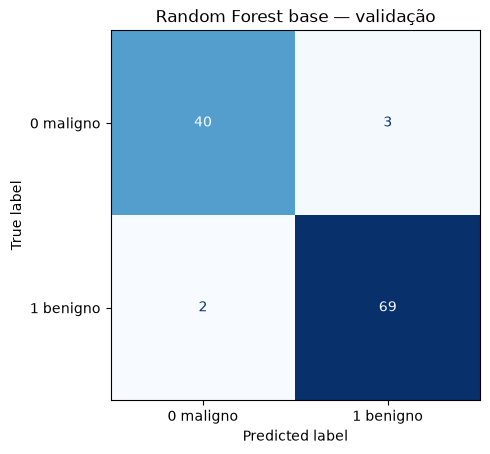

,accuracy,precision,recall,f1,malig→benig (FN),benig→malig (FP),n_estimators,max_depth,acc_treino,f1_cv_treino
modelo,,,,,,,,,,
"RF base (100, None)",0.9561,0.9524,0.9302,0.9412,3,2,100,None,1.0,0.956


In [5]:
def avaliar(modelo, X_, y_, nome):
    """Métricas para a classe maligna (pos_label=0) + matriz de confusão na ordem [0, 1]."""
    pred = modelo.predict(X_)
    cm = confusion_matrix(y_, pred, labels=[0, 1])
    return {
        "modelo": nome,
        "accuracy": accuracy_score(y_, pred),
        "precision": precision_score(y_, pred, pos_label=0),
        "recall": recall_score(y_, pred, pos_label=0),
        "f1": f1_score(y_, pred, pos_label=0),
        "malig→benig (FN)": int(cm[0, 1]),
        "benig→malig (FP)": int(cm[1, 0]),
    }, cm

def plot_cm(cm, titulo, ax=None):
    ConfusionMatrixDisplay(cm, display_labels=["0 maligno", "1 benigno"]).plot(
        ax=ax, cmap="Blues", colorbar=False)
    (ax or plt.gca()).set_title(titulo)

# Validação cruzada estratificada (5 folds) DENTRO do treino: usada só como desempate na Q4
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
f1_maligno = make_scorer(f1_score, pos_label=0)
recall_maligno = make_scorer(recall_score, pos_label=0)

modelos = {}  # nome -> estimador treinado

def rodar(modelo, nome, **info):
    """Treina no treino, avalia na validação e guarda o F1 maligno médio do CV no treino."""
    modelo.fit(X_train, y_train)
    r, cm = avaliar(modelo, X_val, y_val, nome)
    r.update(info)
    r["acc_treino"] = accuracy_score(y_train, modelo.predict(X_train))
    r["f1_cv_treino"] = cross_val_score(clone(modelo), X_train, y_train, cv=cv, scoring=f1_maligno).mean()
    modelos[nome] = modelo
    return r, cm

res_rf_base, cm_rf_base = rodar(
    RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=N_JOBS),
    "RF base (100, None)", n_estimators=100, max_depth=None)

print("Matriz de confusão (linhas = real, colunas = previsto, ordem [0, 1]):")
print(cm_rf_base)
plot_cm(cm_rf_base, "Random Forest base — validação")
plt.show()
pd.DataFrame([res_rf_base]).set_index("modelo").round(4)

In [6]:
resultados_rf = []
for n in [50, 100, 200, 500]:
    for d in [3, 5, None]:
        rf = RandomForestClassifier(n_estimators=n, max_depth=d,
                                    random_state=RANDOM_STATE, n_jobs=N_JOBS)
        r, _ = rodar(rf, f"RF n={n}, depth={d}", n_estimators=n, max_depth=d)
        resultados_rf.append(r)

tab_rf = pd.DataFrame(resultados_rf).set_index("modelo")
tab_rf.round(4)

,accuracy,precision,recall,f1,malig→benig (FN),benig→malig (FP),n_estimators,max_depth,acc_treino,f1_cv_treino
modelo,,,,,,,,,,
"RF n=50, depth=3",0.9561,0.9524,0.9302,0.9412,3,2,50,3.0,0.9883,0.9423
"RF n=50, depth=5",0.9561,0.9524,0.9302,0.9412,3,2,50,5.0,0.9941,0.9561
"RF n=50, depth=None",0.9561,0.9524,0.9302,0.9412,3,2,50,NaN,1.0000,0.9564
"RF n=100, depth=3",0.9561,0.9524,0.9302,0.9412,3,2,100,3.0,0.9853,0.9384
"RF n=100, depth=5",0.9474,0.9302,0.9302,0.9302,3,3,100,5.0,0.9941,0.9556
"RF n=100, depth=None",0.9561,0.9524,0.9302,0.9412,3,2,100,NaN,1.0000,0.9560
"RF n=200, depth=3",0.9474,0.9302,0.9302,0.9302,3,3,200,3.0,0.9853,0.9343
"RF n=200, depth=5",0.9561,0.9524,0.9302,0.9412,3,2,200,5.0,0.9941,0.9518
"RF n=200, depth=None",0.9561,0.9524,0.9302,0.9412,3,2,200,NaN,1.0000,0.9559


### Resposta — Questão 2

**Modelo inicial (`n_estimators=100`, `max_depth=None`) na validação:**

| | prev. maligno | prev. benigno |
|---|---|---|
| **real maligno** | 40 | 3 |
| **real benigno** | 2 | 69 |

Accuracy = 0,9561; precision = 0,9524; recall = 0,9302; F1 = 0,9412 (classe maligna). O modelo deixou passar **3 malignos como benignos** e gerou 2 alarmes falsos.

**Efeito dos parâmetros (12 combinações: `n_estimators` ∈ {50, 100, 200, 500} × `max_depth` ∈ {3, 5, None}):**
- **Na validação, o resultado quase não mudou.** 10 das 12 combinações tiveram exatamente as mesmas métricas do modelo base. As outras duas (100/5 e 200/3) tiveram um alarme falso a mais (F1 = 0,9302). **Todas** erraram os mesmos 3 malignos, o que indica casos difíceis ou de fronteira, e não um problema de configuração.
- **`max_depth`:** com `None`, as árvores crescem até ficarem puras e a accuracy de treino chega a 1,000. Com `max_depth=3`, ela cai para ~0,985. Mesmo memorizando o treino, a floresta profunda não piora na validação. O *bagging* (cada árvore com uma amostra bootstrap e atributos sorteados em cada divisão) seguido da votação média reduz a variância das árvores profundas. Na validação cruzada dentro do treino, as árvores rasas (profundidade 3) tiveram F1 menor (0,931–0,942) que as profundas (0,956–0,960). Isso indica um leve *underfitting* com profundidade 3.
- **`n_estimators`:** acima de ~50 árvores, a validação estabiliza. Mais árvores não causam overfitting no Random Forest, apenas deixam a média de votos mais estável (o F1 do CV sobe levemente até 0,960 com 500 árvores sem profundidade máxima), com custo computacional maior.
- Conclusão: neste conjunto, o Random Forest é robusto aos hiperparâmetros. Com só 114 amostras de validação, diferenças de 1 amostra (~0,9 p.p. de accuracy) não são suficientes para separar as configurações.

## Questão 3 — AdaBoost
- Treine um `AdaBoostClassifier(n_estimators=50, learning_rate=1.0, random_state=42)`.

- obs: `learning_rate`: Peso atribuído a cada classificador em cada iteração de *boosting*. Uma taxa de aprendizado mais alta aumenta a contribuição de cada classificador. Existe um *trade-off* entre os parâmetros `learning_rate` e `n_estimators`.

- Calcule na validação as mesmas métricas e a matriz de confusão da questão 2. Teste pelo menos quatro combinações de `n_estimators` (por exemplo, 50 e 100) e `learning_rate` (por exemplo, 0.1 e 1.0).
- Como os parâmetros alteraram o desempenho? Compare o mecanismo de boosting do AdaBoost com o bagging usado no Random Forest.

Matriz de confusão (linhas = real, colunas = previsto, ordem [0, 1]):
[[40  3]
 [ 1 70]]


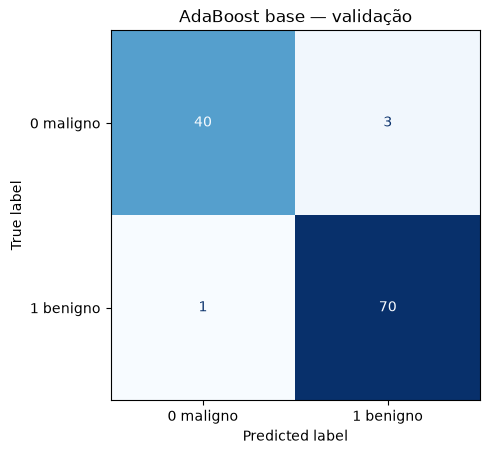

,accuracy,precision,recall,f1,malig→benig (FN),benig→malig (FP),n_estimators,learning_rate,acc_treino,f1_cv_treino
modelo,,,,,,,,,,
"Ada base (50, lr=1.0)",0.9649,0.9756,0.9302,0.9524,3,1,50,1.0,1.0,0.9517


In [7]:
res_ada_base, cm_ada_base = rodar(
    AdaBoostClassifier(n_estimators=50, learning_rate=1.0, random_state=RANDOM_STATE),
    "Ada base (50, lr=1.0)", n_estimators=50, learning_rate=1.0)

print("Matriz de confusão (linhas = real, colunas = previsto, ordem [0, 1]):")
print(cm_ada_base)
plot_cm(cm_ada_base, "AdaBoost base — validação")
plt.show()
pd.DataFrame([res_ada_base]).set_index("modelo").round(4)

In [8]:
resultados_ada = []
for n in [50, 100, 200]:
    for lr in [0.1, 0.5, 1.0]:
        ada = AdaBoostClassifier(n_estimators=n, learning_rate=lr, random_state=RANDOM_STATE)
        r, _ = rodar(ada, f"Ada n={n}, lr={lr}", n_estimators=n, learning_rate=lr)
        resultados_ada.append(r)

tab_ada = pd.DataFrame(resultados_ada).set_index("modelo")
tab_ada.round(4)

,accuracy,precision,recall,f1,malig→benig (FN),benig→malig (FP),n_estimators,learning_rate,acc_treino,f1_cv_treino
modelo,,,,,,,,,,
"Ada n=50, lr=0.1",0.9561,0.9318,0.9535,0.9425,2,3,50,0.1,0.9795,0.9348
"Ada n=50, lr=0.5",0.9649,0.9756,0.9302,0.9524,3,1,50,0.5,1.0000,0.9556
"Ada n=50, lr=1.0",0.9649,0.9756,0.9302,0.9524,3,1,50,1.0,1.0000,0.9517
"Ada n=100, lr=0.1",0.9649,0.9756,0.9302,0.9524,3,1,100,0.1,0.9912,0.9589
"Ada n=100, lr=0.5",0.9737,1.0000,0.9302,0.9639,3,0,100,0.5,1.0000,0.9632
"Ada n=100, lr=1.0",0.9737,0.9762,0.9535,0.9647,2,1,100,1.0,1.0000,0.9641
"Ada n=200, lr=0.1",0.9649,0.9756,0.9302,0.9524,3,1,200,0.1,0.9971,0.9593
"Ada n=200, lr=0.5",0.9649,1.0000,0.9070,0.9512,4,0,200,0.5,1.0000,0.9678
"Ada n=200, lr=1.0",0.9737,0.9762,0.9535,0.9647,2,1,200,1.0,1.0000,0.9642


### Resposta — Questão 3

**Modelo inicial (`n_estimators=50`, `learning_rate=1.0`) na validação:**

| | prev. maligno | prev. benigno |
|---|---|---|
| **real maligno** | 40 | 3 |
| **real benigno** | 1 | 70 |

Accuracy = 0,9649; precision = 0,9756; recall = 0,9302; F1 = 0,9524. Ele erra os mesmos 3 malignos que o Random Forest base, mas tem só 1 alarme falso.

**Como os parâmetros alteraram o desempenho (9 combinações: `n_estimators` ∈ {50, 100, 200} × `learning_rate` ∈ {0,1; 0,5; 1,0}):**
- **Trade-off `learning_rate` × `n_estimators`:** com `lr=0.1` e só 50 estimadores, cada *stump* contribui pouco e o modelo não termina de aprender. A accuracy de treino fica em 0,9795, e o F1 no CV do treino é o menor da grade (0,935), o que indica *underfitting*. Na validação, essa configuração teve 3 alarmes falsos. Com `lr=0.1`, aumentar para 100 e 200 estimadores eleva o F1 do CV (0,959) e reduz os falsos positivos para 1. Ou seja, uma taxa menor exige mais iterações.
- **`lr=1.0` com 100 ou 200 estimadores** teve o melhor resultado na validação: só **2 malignos** previstos como benignos, recall = 0,9535 e F1 = 0,9647 (accuracy 0,9737).
- **`lr=0.5`** com 100 e 200 estimadores chegou a precision = 1,000 (nenhum alarme falso), mas perdeu recall. Com 200 estimadores, deixou passar 4 malignos. A fronteira ficou mais conservadora para prever "maligno".
- A partir de `lr ≥ 0.5`, quase todas as configurações chegam a 100% de accuracy no treino e ainda generalizam bem. É o comportamento conhecido do AdaBoost: ele continua aumentando a margem das previsões mesmo depois de zerar o erro de treino. As variações na validação são de 1 ou 2 amostras, então devem ser lidas com cautela.

**Boosting (AdaBoost) × bagging (Random Forest):**

| | Random Forest (bagging) | AdaBoost (boosting) |
|---|---|---|
| Construção | Árvores **independentes e em paralelo**, cada uma numa amostra *bootstrap* com sorteio de atributos | Estimadores **sequenciais**: cada um é treinado depois do anterior |
| Foco | Diversidade por aleatoriedade | Os **pesos das amostras mal classificadas aumentam**, e o próximo estimador se concentra nelas |
| Estimador base | Árvores profundas (baixo viés, alta variância) | Árvores rasas, *stumps* de profundidade 1 (alto viés, baixa variância) |
| Combinação | Voto/média com pesos iguais | Voto **ponderado**: cada estimador recebe um peso α proporcional à sua precisão, multiplicado pelo `learning_rate` |
| Reduz principalmente | **Variância** | **Viés** |
| Risco | Pouco sensível a hiperparâmetros | Sensível a ruído/outliers (que recebem pesos cada vez maiores) e ao par `learning_rate`/`n_estimators` |

Isso aparece nos resultados. O RF mal reagiu aos hiperparâmetros, porque a média de árvores independentes já é estável. O AdaBoost variou mais (FN de 2 a 4), porque cada configuração muda a sequência de reponderações.

## Questão 4 — Analise os erros e escolha configurações
- Construa uma tabela de validação com os modelos iniciais e as configurações testadas, contendo accuracy, precision, recall, F1 para a classe maligna e número de **malignos previstos como benignos**. Explique por que accuracy sozinha pode ocultar um erro relevante.
- Escolha uma configuração final de cada algoritmo com um critério explícito; em caso de empate, explique como desempata. Não use o conjunto de teste para esta escolha. (Aqui você pode usar o `RandomizedSearchCV` do scikit-learn para busca dos melhores hiper-parâmetros, que testa combinações aleatórias de hiperparâmetros dentro de um intervalo definido.)

In [9]:
# Busca aleatória com validação cruzada estratificada SOMENTE no treino (teste intocado)
scoring = {"recall_mal": recall_maligno, "f1_mal": f1_maligno}

busca_rf = RandomizedSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE),
    {"n_estimators": randint(50, 501), "max_depth": [3, 5, 8, 12, None],
     "max_features": ["sqrt", "log2", None], "min_samples_leaf": randint(1, 6)},
    n_iter=30, scoring=scoring, refit="f1_mal", cv=cv,
    random_state=RANDOM_STATE, n_jobs=N_JOBS)
busca_rf.fit(X_train, y_train)

busca_ada = RandomizedSearchCV(
    AdaBoostClassifier(random_state=RANDOM_STATE),
    {"n_estimators": randint(50, 501), "learning_rate": uniform(0.05, 1.45)},
    n_iter=30, scoring=scoring, refit="f1_mal", cv=cv,
    random_state=RANDOM_STATE, n_jobs=N_JOBS)
busca_ada.fit(X_train, y_train)

print("RF  — melhores parâmetros (F1 maligno médio no CV = %.4f):" % busca_rf.best_score_, busca_rf.best_params_)
print("Ada — melhores parâmetros (F1 maligno médio no CV = %.4f):" % busca_ada.best_score_, busca_ada.best_params_)

RF  — melhores parâmetros (F1 maligno médio no CV = 0.9600): {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'n_estimators': 264}
Ada — melhores parâmetros (F1 maligno médio no CV = 0.9755): {'learning_rate': np.float64(0.6664760180123048), 'n_estimators': 103}


In [10]:
def registrar_busca(busca, nome, **info):
    r, _ = avaliar(busca.best_estimator_, X_val, y_val, nome)
    r.update(info)
    r["acc_treino"] = accuracy_score(y_train, busca.best_estimator_.predict(X_train))
    r["f1_cv_treino"] = busca.best_score_
    modelos[nome] = busca.best_estimator_
    return r

res_rs_rf = registrar_busca(busca_rf, "RF RandomizedSearch", n_estimators=busca_rf.best_params_["n_estimators"],
                            max_depth=busca_rf.best_params_["max_depth"])
res_rs_ada = registrar_busca(busca_ada, "Ada RandomizedSearch", n_estimators=busca_ada.best_params_["n_estimators"],
                             learning_rate=round(busca_ada.best_params_["learning_rate"], 4))

colunas = ["accuracy", "precision", "recall", "f1", "malig→benig (FN)", "benig→malig (FP)", "f1_cv_treino", "n_estimators"]
tab_val = pd.concat([
    pd.DataFrame([res_rf_base, res_ada_base]).set_index("modelo"),
    tab_rf, tab_ada,
    pd.DataFrame([res_rs_rf, res_rs_ada]).set_index("modelo"),
])
tab_val.insert(0, "algoritmo", ["RF" if m.startswith("RF") else "Ada" for m in tab_val.index])
tab_val[["algoritmo"] + colunas].round(4).sort_values(["algoritmo", "malig→benig (FN)", "f1"],
                                                     ascending=[True, True, False])

,algoritmo,accuracy,precision,recall,f1,malig→benig (FN),benig→malig (FP),f1_cv_treino,n_estimators
modelo,,,,,,,,,
"Ada n=100, lr=1.0",Ada,0.9737,0.9762,0.9535,0.9647,2,1,0.9641,100
"Ada n=200, lr=1.0",Ada,0.9737,0.9762,0.9535,0.9647,2,1,0.9642,200
"Ada n=50, lr=0.1",Ada,0.9561,0.9318,0.9535,0.9425,2,3,0.9348,50
"Ada n=100, lr=0.5",Ada,0.9737,1.0000,0.9302,0.9639,3,0,0.9632,100
Ada RandomizedSearch,Ada,0.9737,1.0000,0.9302,0.9639,3,0,0.9755,103
"Ada base (50, lr=1.0)",Ada,0.9649,0.9756,0.9302,0.9524,3,1,0.9517,50
"Ada n=50, lr=0.5",Ada,0.9649,0.9756,0.9302,0.9524,3,1,0.9556,50
"Ada n=50, lr=1.0",Ada,0.9649,0.9756,0.9302,0.9524,3,1,0.9517,50
"Ada n=100, lr=0.1",Ada,0.9649,0.9756,0.9302,0.9524,3,1,0.9589,100


In [11]:
# Critério explícito de escolha (sem usar o teste):
#   1) menor nº de malignos previstos como benignos (FN) na validação -> maior recall maligno
#   2) empate: maior F1 da classe maligna na validação
#   3) empate: maior F1 maligno médio na validação cruzada de 5 folds dentro do treino
#   4) empate: modelo mais simples/barato (menor n_estimators)
def escolher(tab):
    return tab.sort_values(["malig→benig (FN)", "f1", "f1_cv_treino", "n_estimators"],
                           ascending=[True, False, False, True], kind="stable")

rank_rf = escolher(tab_val[tab_val["algoritmo"] == "RF"])
rank_ada = escolher(tab_val[tab_val["algoritmo"] == "Ada"])
print("Top 5 Random Forest:")
display(rank_rf[colunas].head(5).round(4))
print("Top 5 AdaBoost:")
display(rank_ada[colunas].head(5).round(4))
escolha_rf, escolha_ada = rank_rf.index[0], rank_ada.index[0]
print("Escolhidos ->", escolha_rf, "|", escolha_ada)

Top 5 Random Forest:


,accuracy,precision,recall,f1,malig→benig (FN),benig→malig (FP),f1_cv_treino,n_estimators
modelo,,,,,,,,
"RF n=500, depth=None",0.9561,0.9524,0.9302,0.9412,3,2,0.9600,500
RF RandomizedSearch,0.9561,0.9524,0.9302,0.9412,3,2,0.9600,264
"RF n=50, depth=None",0.9561,0.9524,0.9302,0.9412,3,2,0.9564,50
"RF n=50, depth=5",0.9561,0.9524,0.9302,0.9412,3,2,0.9561,50
"RF base (100, None)",0.9561,0.9524,0.9302,0.9412,3,2,0.9560,100


Top 5 AdaBoost:


,accuracy,precision,recall,f1,malig→benig (FN),benig→malig (FP),f1_cv_treino,n_estimators
modelo,,,,,,,,
"Ada n=200, lr=1.0",0.9737,0.9762,0.9535,0.9647,2,1,0.9642,200
"Ada n=100, lr=1.0",0.9737,0.9762,0.9535,0.9647,2,1,0.9641,100
"Ada n=50, lr=0.1",0.9561,0.9318,0.9535,0.9425,2,3,0.9348,50
Ada RandomizedSearch,0.9737,1.0000,0.9302,0.9639,3,0,0.9755,103
"Ada n=100, lr=0.5",0.9737,1.0000,0.9302,0.9639,3,0,0.9632,100


Escolhidos -> RF n=500, depth=None | Ada n=200, lr=1.0


In [12]:
# Configurações finais: mesmos hiperparâmetros escolhidos, estimador ainda não treinado
rf_final, ada_final = clone(modelos[escolha_rf]), clone(modelos[escolha_ada])
print(rf_final)
print(ada_final)

RandomForestClassifier(n_estimators=500, n_jobs=8, random_state=42)
AdaBoostClassifier(n_estimators=200, random_state=42)


### Resposta — Questão 4

**Tabela de validação:** a tabela acima reúne os 2 modelos iniciais, as 21 configurações testadas nas questões 2 e 3 e o melhor modelo do `RandomizedSearchCV` de cada algoritmo (30 combinações cada, CV estratificado de 5 folds **só no treino**, otimizando o F1 maligno). Ela mostra accuracy, precision, recall, F1 da classe maligna e **malignos previstos como benignos (FN)**.

**Por que accuracy sozinha esconde um erro relevante:**
- Ela trata igualmente os dois tipos de erro. Neste problema, classificar um tumor **maligno como benigno** (FN) é muito mais grave que um alarme falso (FP), porque o primeiro pode atrasar o tratamento.
- Exemplos da tabela: `Ada n=200, lr=0.5` tem a **mesma accuracy** (0,9649) do AdaBoost base, mas deixa passar **4 malignos** em vez de 3. Já `Ada n=50, lr=0.1` tem accuracy **menor** (0,9561) que `Ada n=100, lr=0.5` (0,9737), mas erra **menos malignos** (2 contra 3). Escolher pela accuracy levaria ao modelo que perde mais câncer.
- Com desbalanceamento, um classificador que sempre responde "benigno" teria 62% de accuracy (71/114) e recall de malignos igual a **0**.

**Critério explícito de escolha (sem usar o teste):**
1. **Menor número de malignos previstos como benignos (FN)** na validação, ou seja, maior recall maligno. Essa é a prioridade clínica.
2. Empate → **maior F1 da classe maligna** na validação (equilíbrio com a precision, para não aceitar um excesso de alarmes falsos).
3. Empate → **maior F1 maligno médio na validação cruzada de 5 folds dentro do treino**. Com só 114 amostras, a validação produz muitos empates exatos. O CV usa 5 partições diferentes e dá uma estimativa mais estável, ainda sem tocar no teste.
4. Empate → **menor `n_estimators`** (modelo mais simples e barato).

**Configurações escolhidas:**
- **Random Forest → `n_estimators=500`, `max_depth=None`.** Todas as configurações de RF empataram em FN = 3, e 11 delas empataram também em F1 = 0,9412 na validação. O desempate pelo CV escolheu a de 500 árvores (F1 CV ≈ 0,960), praticamente empatada com o `RandomizedSearch` (264 árvores, `min_samples_leaf=2`, também ≈ 0,960). Isso confirma que mais árvores sem limite de profundidade é a escolha mais estável.
- **AdaBoost → `n_estimators=200`, `learning_rate=1.0`.** Ele empatou com `n=100, lr=1.0` em FN = 2 e F1 = 0,9647 na validação. No CV, os dois também ficaram praticamente iguais (0,9642 contra 0,9641), e o critério 3 escolheu 200 por uma diferença desprezível. Na prática, os dois são equivalentes. A configuração do `RandomizedSearch` (`lr≈0.67`, 103 estimadores) teve o melhor F1 no CV (0,9755), mas errou 3 malignos na validação e foi descartada pelo critério 1, que prioriza o FN.

Os hiperparâmetros escolhidos são então **re-treinados em treino + validação (80% dos dados)**, para aproveitar mais amostras, antes da avaliação única no teste.

## Questão 5 — Avaliação final
- Avalie **uma única vez** no conjunto de teste as duas configurações escolhidas na questão 4. Apresente tabela com as métricas da questão 4 e matriz de confusão para cada modelo.
- Qual algoritmo escolheria neste experimento? Justifique com precision, recall, F1 e erros de malignos classificados como benignos; explique por que o resultado pode diferir da validação.

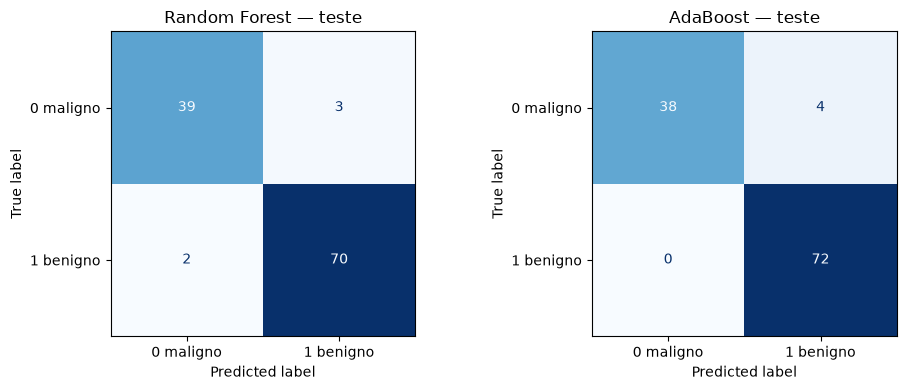

,accuracy,precision,recall,f1,malig→benig (FN),benig→malig (FP)
modelo,,,,,,
"Random Forest (RF n=500, depth=None)",0.9561,0.9512,0.9286,0.9398,3,2
"AdaBoost (Ada n=200, lr=1.0)",0.9649,1.0000,0.9048,0.9500,4,0


In [13]:
# Hiperparâmetros já fixados -> re-treina em treino + validação (80%) e avalia UMA única vez no teste
X_trval = pd.concat([X_train, X_val]); y_trval = pd.concat([y_train, y_val])
rf_final.fit(X_trval, y_trval)
ada_final.fit(X_trval, y_trval)

res_t_rf, cm_t_rf = avaliar(rf_final, X_test, y_test, f"Random Forest ({escolha_rf})")
res_t_ada, cm_t_ada = avaliar(ada_final, X_test, y_test, f"AdaBoost ({escolha_ada})")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
plot_cm(cm_t_rf, "Random Forest — teste", axes[0])
plot_cm(cm_t_ada, "AdaBoost — teste", axes[1])
plt.tight_layout(); plt.show()

tab_teste = pd.DataFrame([res_t_rf, res_t_ada]).set_index("modelo")
tab_teste.round(4)

In [14]:
# Comparação validação x teste para os modelos escolhidos
comp = pd.DataFrame({
    "F1 validação": [tab_val.loc[escolha_rf, "f1"], tab_val.loc[escolha_ada, "f1"]],
    "F1 teste": [res_t_rf["f1"], res_t_ada["f1"]],
    "FN validação": [tab_val.loc[escolha_rf, "malig→benig (FN)"], tab_val.loc[escolha_ada, "malig→benig (FN)"]],
    "FN teste": [res_t_rf["malig→benig (FN)"], res_t_ada["malig→benig (FN)"]],
}, index=["Random Forest", "AdaBoost"])
comp.round(4)

,F1 validação,F1 teste,FN validação,FN teste
Random Forest,0.9412,0.9398,3,3
AdaBoost,0.9647,0.9500,2,4


### Resposta — Questão 5

**Resultado no teste (avaliado uma única vez):**

| Modelo | Accuracy | Precision | Recall | F1 | Malignos → benignos (FN) | Benignos → malignos (FP) |
|---|---|---|---|---|---|---|
| Random Forest (500, None) | 0,9561 | 0,9512 | **0,9286** | 0,9398 | **3** | 2 |
| AdaBoost (200, lr=1.0) | **0,9649** | **1,0000** | 0,9048 | **0,9500** | 4 | **0** |

Matrizes de confusão no teste (ordem [0, 1]): RF = [[39, 3], [2, 70]]; AdaBoost = [[38, 4], [0, 72]].

**Qual algoritmo escolher?** Pelo critério definido na Questão 4, **o Random Forest**:
- Ele deixou passar **3 malignos** contra **4** do AdaBoost, com recall de 0,9286 contra 0,9048. Neste problema, esse é o erro que mais importa.
- O AdaBoost tem melhor precision (1,000, nenhum alarme falso), melhor F1 (0,950 contra 0,940) e melhor accuracy. Ele seria preferível se o custo dos dois erros fosse parecido. Mas o ganho dele vem de **evitar falsos positivos**, que aqui são o erro menos grave, e não de detectar mais malignos.
- Ressalva importante: a diferença é de **um único paciente** em 42 malignos. Estatisticamente, os dois modelos estão empatados neste experimento. A escolha do RF também tem a vantagem de ele ter sido o mais estável entre configurações e entre validação e teste (FN = 3 nos dois conjuntos).

**Por que o resultado pode diferir da validação?** Na validação, o AdaBoost tinha errado só 2 malignos e parecia melhor. No teste, errou 4. Possíveis razões:
1. **Conjuntos pequenos:** validação e teste têm ~43 malignos cada, e um caso a mais ou a menos muda o recall em ~2,4 p.p. Grande parte da diferença observada é ruído amostral.
2. **Viés de seleção (otimismo da validação):** escolhemos a melhor entre ~25 configurações olhando para o mesmo conjunto de validação. A vencedora tende a ser a que "teve sorte" naquelas 114 amostras, e o desempenho dela no teste naturalmente cai, o que é mais visível no AdaBoost, cujas configurações variaram mais.
3. **Modelo re-treinado:** o modelo final foi re-treinado com treino + validação, então não é exatamente o mesmo avaliado na validação.
4. **Sensibilidade do boosting:** ao reponderar amostras difíceis, o AdaBoost reage mais a casos de fronteira ou atípicos, que podem estar distribuídos de forma diferente entre validação e teste.

Por isso, o teste é usado só uma vez, como estimativa final sem viés. E como os dados são didáticos e pequenos, essa comparação **não constitui validação clínica**. Uma conclusão robusta exigiria validação cruzada repetida ou mais dados, além de ajustar o limiar de decisão para priorizar o recall de malignos.